In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

sessions = pd.read_csv("../data/raw/sessions.csv")
events = pd.read_csv("../data/raw/events.csv")

print("Sessions shape:", sessions.shape)
print("Events shape:", events.shape)

display(sessions.head())
display(events.head())

Sessions shape: (10000, 11)
Events shape: (30913, 8)


,session_id,customer_id,session_start,device_type,product_id,product_category,product_price,quantity,discount_pct,shipping_charge,cart_id
0,S00001,C07463,2026-10-28 21:44:54,Desktop,P0259,Home & Kitchen,11319.54,1,0,0,CART00001
1,S00002,C02242,2026-10-23 23:08:05,Mobile,P0471,Home & Kitchen,13866.27,1,0,0,CART00002
2,S00003,C03909,2026-10-07 09:58:13,Desktop,P0044,Fashion,4175.46,2,5,79,NaN
3,S00004,C00317,2026-10-31 20:52:48,Desktop,P0385,Fashion,1498.63,2,10,79,CART00004
4,S00005,C01337,2026-10-31 18:32:43,Mobile,P0280,Electronics,51483.23,1,0,0,CART00005


,event_id,session_id,event_name,event_timestamp,payment_method,payment_status,payment_failure_reason,order_id
0,E0000001,S00001,product_view,2026-10-28 21:44:54,NaN,NaN,NaN,NaN
1,E0000002,S00001,add_to_cart,2026-10-28 21:47:54,NaN,NaN,NaN,NaN
2,E0000003,S00002,product_view,2026-10-23 23:08:05,NaN,NaN,NaN,NaN
3,E0000004,S00002,add_to_cart,2026-10-23 23:14:05,NaN,NaN,NaN,NaN
4,E0000005,S00003,product_view,2026-10-07 09:58:13,NaN,NaN,NaN,NaN


In [5]:
print("Sessions:", sessions.shape)
print("Events:", events.shape)

print("\nSession columns:")
print(sessions.columns.tolist())

print("\nEvent columns:")
print(events.columns.tolist())

Sessions: (10000, 11)
Events: (30913, 8)

Session columns:
['session_id', 'customer_id', 'session_start', 'device_type', 'product_id', 'product_category', 'product_price', 'quantity', 'discount_pct', 'shipping_charge', 'cart_id']

Event columns:
['event_id', 'session_id', 'event_name', 'event_timestamp', 'payment_method', 'payment_status', 'payment_failure_reason', 'order_id']


In [6]:
print("SESSIONS DATA")
sessions.info()

print("\nEVENTS DATA")
events.info()

SESSIONS DATA
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   session_id        10000 non-null  str    
 1   customer_id       10000 non-null  str    
 2   session_start     10000 non-null  str    
 3   device_type       10000 non-null  str    
 4   product_id        10000 non-null  str    
 5   product_category  10000 non-null  str    
 6   product_price     10000 non-null  float64
 7   quantity          10000 non-null  int64  
 8   discount_pct      10000 non-null  int64  
 9   shipping_charge   10000 non-null  int64  
 10  cart_id           6969 non-null   str    
dtypes: float64(1), int64(3), str(7)
memory usage: 859.5 KB

EVENTS DATA
<class 'pandas.DataFrame'>
RangeIndex: 30913 entries, 0 to 30912
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   e

In [7]:
print("Missing values in Sessions:")
print(sessions.isnull().sum())

print("\nMissing values in Events:")
print(events.isnull().sum())

print("\nDuplicate rows in Sessions:", sessions.duplicated().sum())
print("Duplicate rows in Events:", events.duplicated().sum())

Missing values in Sessions:
session_id             0
customer_id            0
session_start          0
device_type            0
product_id             0
product_category       0
product_price          0
quantity               0
discount_pct           0
shipping_charge        0
cart_id             3031
dtype: int64

Missing values in Events:
event_id                      0
session_id                    0
event_name                    0
event_timestamp               0
payment_method            22459
payment_status            22459
payment_failure_reason    30567
order_id                  26859
dtype: int64

Duplicate rows in Sessions: 0
Duplicate rows in Events: 0


Funnel Analysis

In [8]:
funnel = events.groupby("event_name")["session_id"].nunique()

stages = [
    "product_view",
    "add_to_cart",
    "checkout_initiated",
    "payment_initiated",
    "purchase_completed"
]

for stage in stages:
    print(stage, ":", funnel.get(stage, 0))

product_view : 10000
add_to_cart : 6969
checkout_initiated : 5490
payment_initiated : 4400
purchase_completed : 4054


In [9]:
for i in range(len(stages) - 1):

    current = funnel.get(stages[i], 0)
    next_stage = funnel.get(stages[i + 1], 0)

    conversion = (next_stage / current) * 100
    dropoff = 100 - conversion

    print(f"\n{stages[i]} -> {stages[i+1]}")
    print("Conversion Rate:", round(conversion, 2), "%")
    print("Drop-off Rate:", round(dropoff, 2), "%")


product_view -> add_to_cart
Conversion Rate: 69.69 %
Drop-off Rate: 30.31 %

add_to_cart -> checkout_initiated
Conversion Rate: 78.78 %
Drop-off Rate: 21.22 %

checkout_initiated -> payment_initiated
Conversion Rate: 80.15 %
Drop-off Rate: 19.85 %

payment_initiated -> purchase_completed
Conversion Rate: 92.14 %
Drop-off Rate: 7.86 %


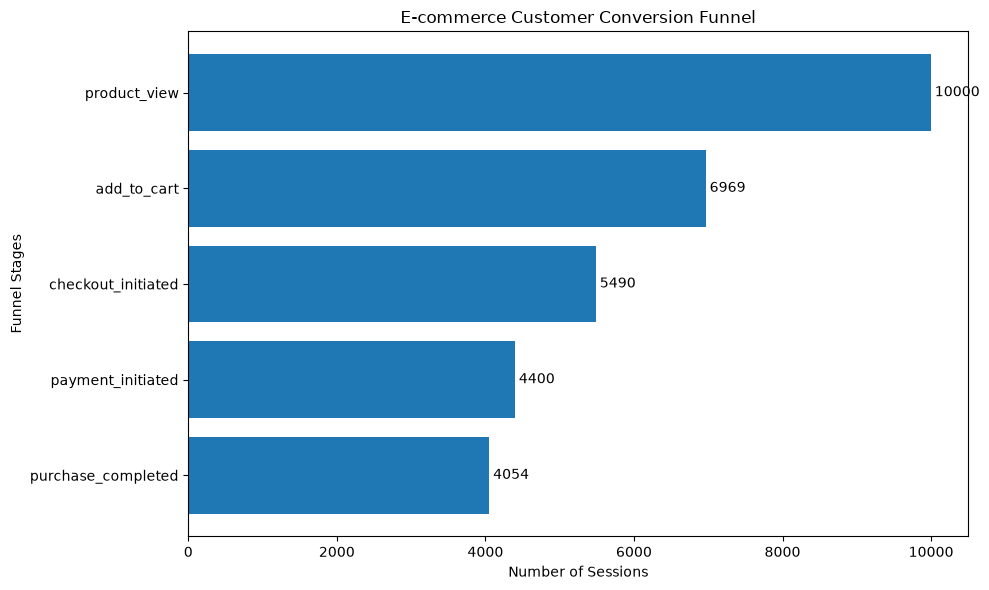

In [13]:
counts = [funnel.get(stage, 0) for stage in stages]

plt.figure(figsize=(10, 6))

plt.barh(stages, counts)

plt.xlabel("Number of Sessions")
plt.ylabel("Funnel Stages")
plt.title("E-commerce Customer Conversion Funnel")

plt.gca().invert_yaxis()

for i, count in enumerate(counts):
    plt.text(count + 50, i, str(count), va='center')

plt.tight_layout()
plt.show()

Device-wise Conversion Analysis

In [14]:
device_counts = sessions["device_type"].value_counts()
print(device_counts)

device_type
Mobile     6048
Desktop    2967
Tablet      985
Name: count, dtype: int64


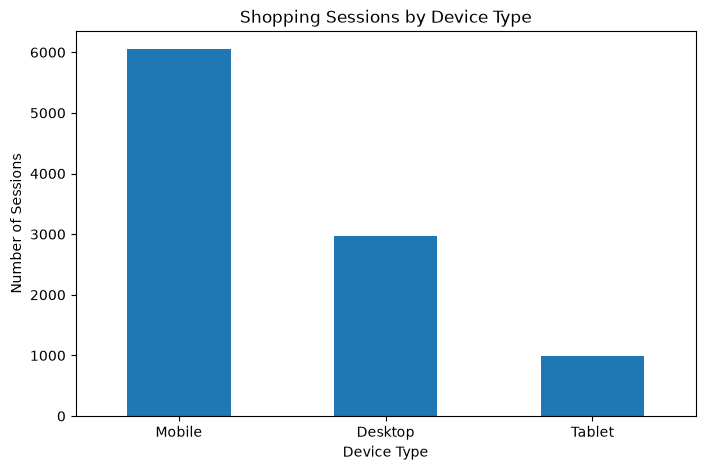

In [15]:
device_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Shopping Sessions by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

In [16]:
# Merge sessions with events

merged = events.merge(
    sessions[["session_id", "device_type"]],
    on="session_id",
    how="left"
)

# Find sessions that added products to cart
cart_sessions = merged[
    merged["event_name"] == "add_to_cart"
]

# Find sessions that completed purchases
purchase_sessions = merged[
    merged["event_name"] == "purchase_completed"
]

# Calculate device-wise cart sessions
cart_by_device = cart_sessions.groupby(
    "device_type"
)["session_id"].nunique()

# Calculate device-wise purchase sessions
purchase_by_device = purchase_sessions.groupby(
    "device_type"
)["session_id"].nunique()

# Calculate abandonment rate
device_analysis = pd.DataFrame({
    "Cart Sessions": cart_by_device,
    "Purchase Sessions": purchase_by_device
}).fillna(0)

device_analysis["Abandoned Sessions"] = (
    device_analysis["Cart Sessions"] -
    device_analysis["Purchase Sessions"]
)

device_analysis["Abandonment Rate (%)"] = (
    device_analysis["Abandoned Sessions"] /
    device_analysis["Cart Sessions"] * 100
)

display(device_analysis.round(2))

,Cart Sessions,Purchase Sessions,Abandoned Sessions,Abandonment Rate (%)
device_type,,,,
Desktop,2171,1372,799,36.80
Mobile,4101,2240,1861,45.38
Tablet,697,442,255,36.59


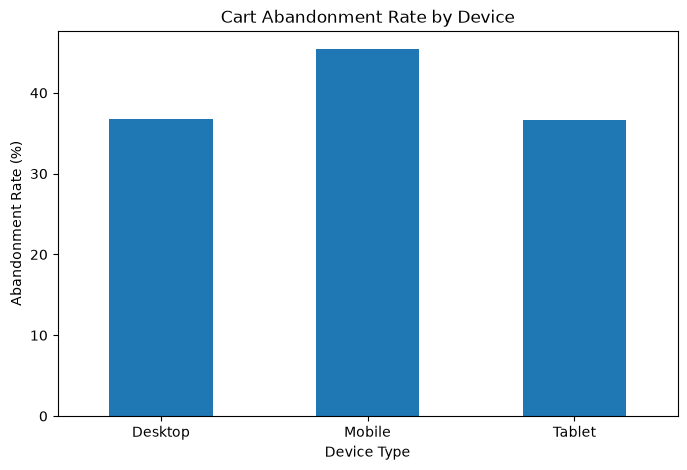

In [17]:
device_analysis["Abandonment Rate (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Cart Abandonment Rate by Device")
plt.xlabel("Device Type")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=0)

plt.show()